<a href="https://colab.research.google.com/github/LexDomingues/Clothing-Recommendation-System/blob/main/Clothing_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers
!pip install -q transformers kagglehub

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

from PIL import Image
from transformers import AutoImageProcessor, AutoModel

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "ryanbadai/clothes-dataset"
)

dataset_path = os.path.join(
    path,
    "Clothes_Dataset"
)

print("Dataset:", dataset_path)

100%|██████████| 1.37G/1.37G [01:13<00:00, 20.1MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/ryanbadai/clothes-dataset/versions/1/Clothes_Dataset


In [ ]:
image_paths = []
categories = []

for category in sorted(os.listdir(dataset_path)):

    category_path = os.path.join(
        dataset_path,
        category
    )

    if not os.path.isdir(category_path):
        continue

    for filename in sorted(os.listdir(category_path)):

        image_path = os.path.join(
            category_path,
            filename
        )

        image_paths.append(image_path)
        categories.append(category)

image_paths = np.array(image_paths)
categories = np.array(categories)

print("Total number of images:", len(image_paths))
print("Total number of categories:", len(np.unique(categories)))
print("Categories:", np.unique(categories))

Total number of images: 7500
Total number of categories: 15
Categories: ['Blazer' 'Celana_Panjang' 'Celana_Pendek' 'Gaun' 'Hoodie' 'Jaket'
 'Jaket_Denim' 'Jaket_Olahraga' 'Jeans' 'Kaos' 'Kemeja' 'Mantel' 'Polo'
 'Rok' 'Sweter']


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
model_name = "facebook/dinov2-small"

processor = AutoImageProcessor.from_pretrained(model_name)

dinov2 = AutoModel.from_pretrained(model_name)

dinov2 = dinov2.to(device)

dinov2.eval()

print("DINOv2 loaded!")

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2 loaded!


In [ ]:
dinov2_embeddings = np.empty((len(image_paths), 384), dtype=np.float32)

print("Matrix format:", dinov2_embeddings.shape)

Matrix format: (7500, 384)


In [ ]:
batch_size = 16

for start in range(0, len(image_paths), batch_size):
    end = min(start + batch_size, len(image_paths))
    batch_paths = image_paths[start:end]

    batch_images = []

    for image_path in batch_paths:
        with Image.open(image_path) as img:
            batch_images.append(img.convert("RGB"))

    inputs = processor(images=batch_images, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():
        outputs = dinov2(pixel_values=pixel_values)
        batch_embeddings = outputs.pooler_output

    dinov2_embeddings[start:end] = batch_embeddings.cpu().numpy()

    if start == 0:
        print("Images format:", pixel_values.shape)
        print("Embeddings format:", batch_embeddings.shape)
        print("First values:", batch_embeddings[0][:10].cpu().numpy())

    if end % 160 == 0 or end == len(image_paths):
        print(f"Processed images: {end}/{len(image_paths)}")

    del batch_images, inputs, pixel_values, outputs, batch_embeddings

Images format: torch.Size([16, 3, 224, 224])
Embeddings format: torch.Size([16, 384])
First values: [ 1.42673    2.2142396 -1.1231698  1.9877731 -6.4994574 -1.2745337
  3.2884028  0.7206984  5.1363277  2.0435367]
Processed images: 160/7500
Processed images: 320/7500
Processed images: 480/7500
Processed images: 640/7500
Processed images: 800/7500
Processed images: 960/7500
Processed images: 1120/7500
Processed images: 1280/7500
Processed images: 1440/7500
Processed images: 1600/7500
Processed images: 1760/7500
Processed images: 1920/7500
Processed images: 2080/7500
Processed images: 2240/7500
Processed images: 2400/7500
Processed images: 2560/7500
Processed images: 2720/7500
Processed images: 2880/7500
Processed images: 3040/7500
Processed images: 3200/7500
Processed images: 3360/7500
Processed images: 3520/7500
Processed images: 3680/7500
Processed images: 3840/7500
Processed images: 4000/7500
Processed images: 4160/7500
Processed images: 4320/7500
Processed images: 4480/7500
Processed

In [ ]:
norms = np.linalg.norm(dinov2_embeddings, axis=1, keepdims=True)

normalized_dinov2_embeddings = dinov2_embeddings / np.maximum(norms, 1e-10)

print("Format:", normalized_dinov2_embeddings.shape)
print("Norm of the first embedding:", np.linalg.norm(normalized_dinov2_embeddings[0]))

Format: (7500, 384)
Norm of the first embedding: 1.0


In [ ]:
def find_similar_images_dinov2(query_index, top_n=5):

    query_embedding = normalized_dinov2_embeddings[query_index]

    similarities = normalized_dinov2_embeddings @ query_embedding

    query_category = categories[query_index]

    same_category = categories == query_category

    similarities[~same_category] = -1

    similarities[query_index] = -1

    similar_indices = np.argsort(similarities)[::-1][:top_n]

    return similar_indices, similarities[similar_indices]

In [ ]:
def show_similar_images_dinov2(query_index, top_n=5):

    similar_indices, scores = find_similar_images_dinov2(
        query_index, top_n
    )

    fig, axes = plt.subplots(1, top_n + 1, figsize=(18, 4))

    original = Image.open(image_paths[query_index]).convert("RGB")

    axes[0].imshow(original)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    for i, (index, score) in enumerate(zip(similar_indices, scores)):

        img = Image.open(image_paths[index]).convert("RGB")

        axes[i + 1].imshow(img)
        axes[i + 1].set_title(f"Similarity: {score:.4f}")
        axes[i + 1].axis("off")

    plt.suptitle(f"Category: {categories[query_index]}")
    plt.tight_layout()
    plt.show()

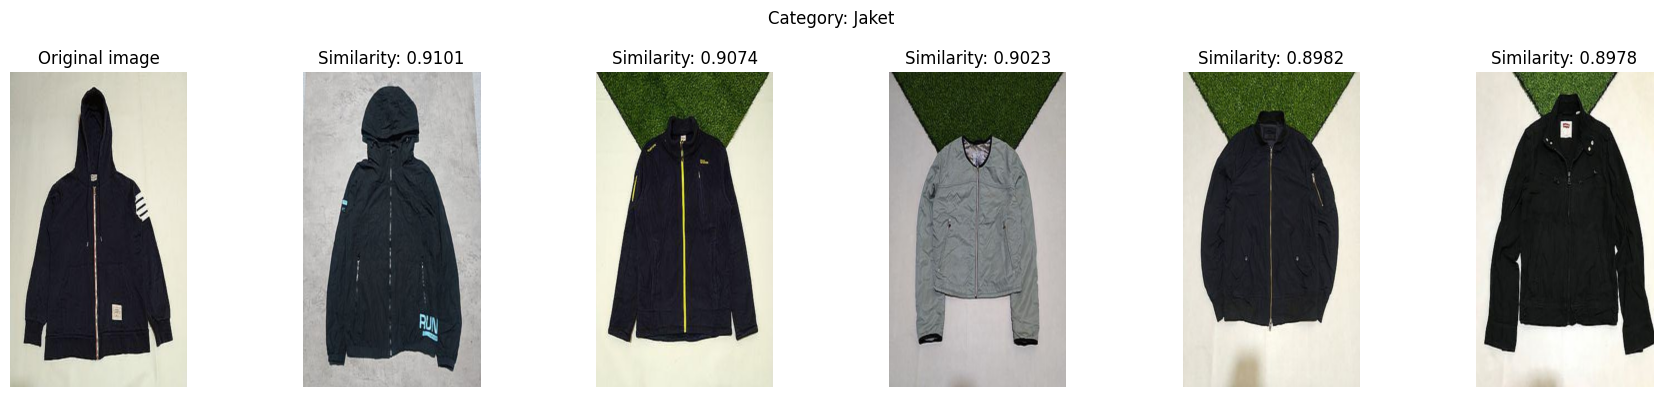

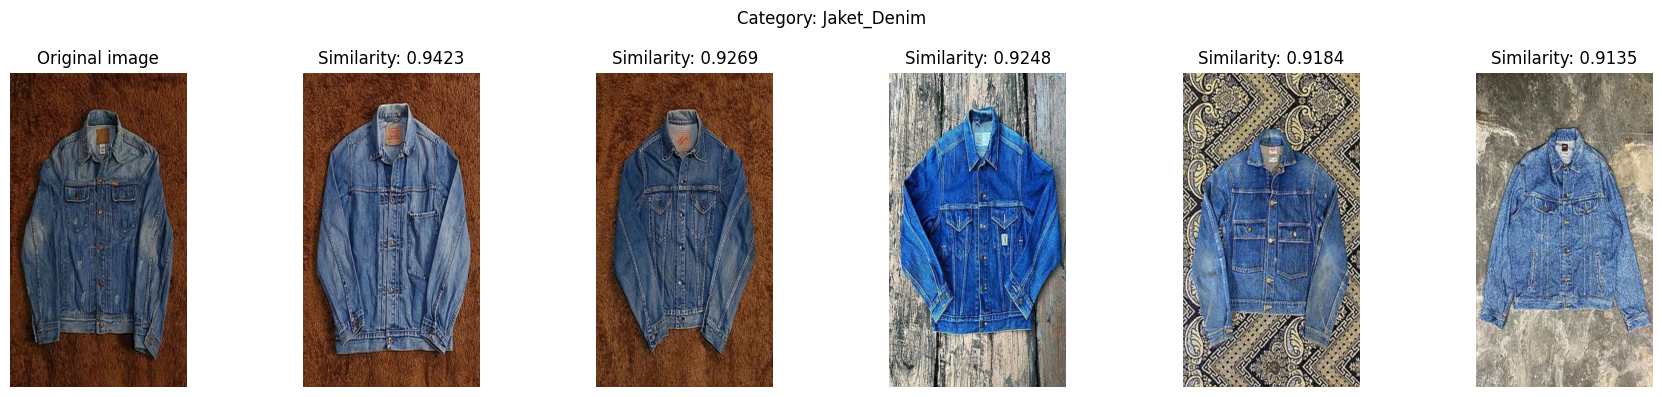

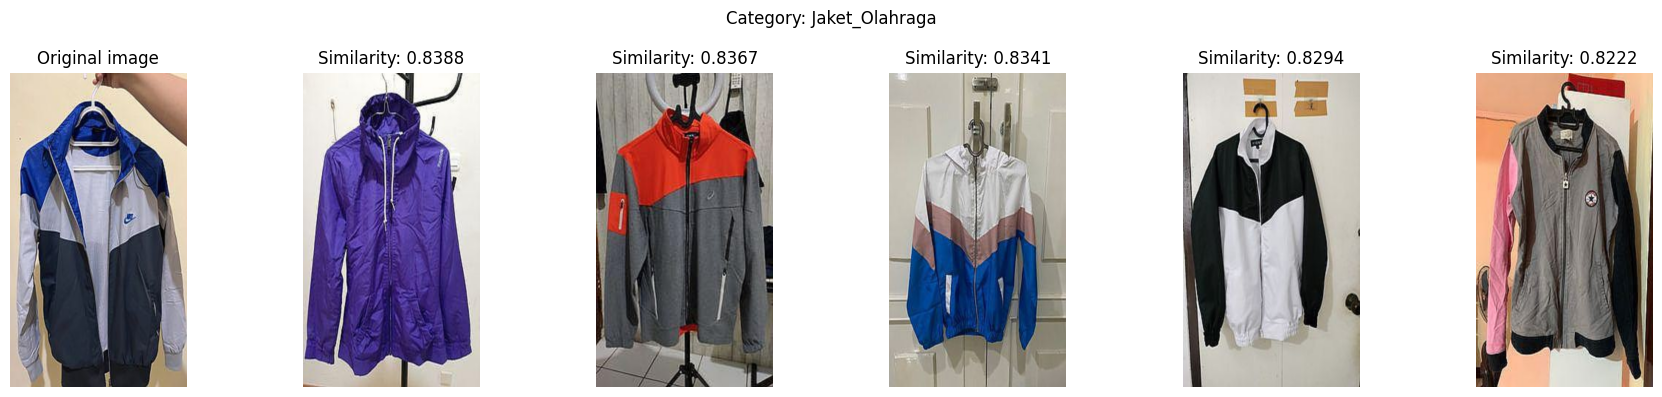

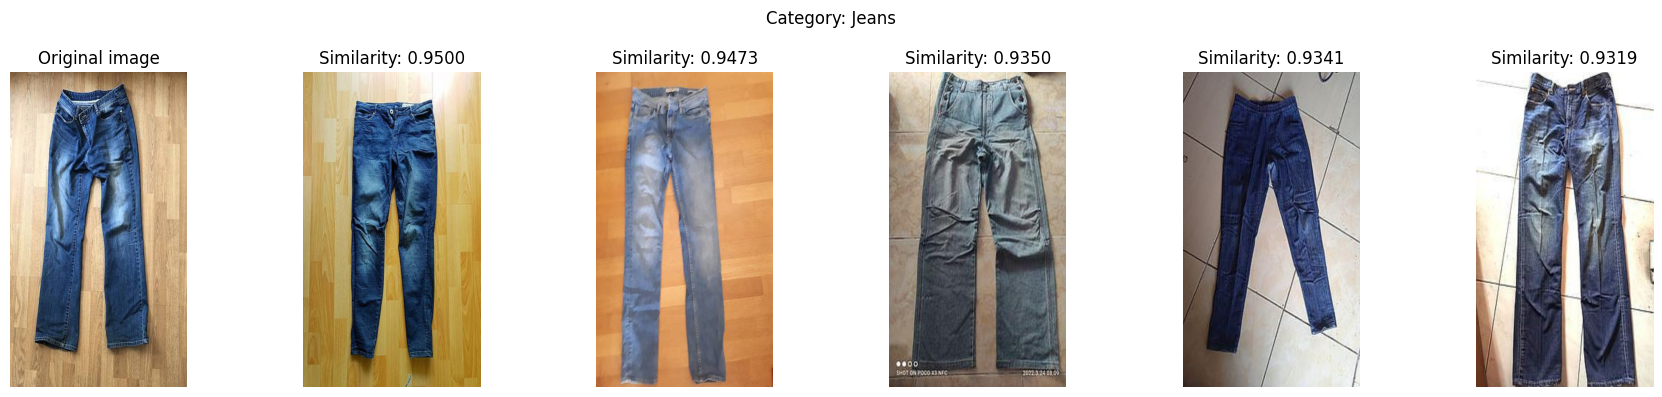

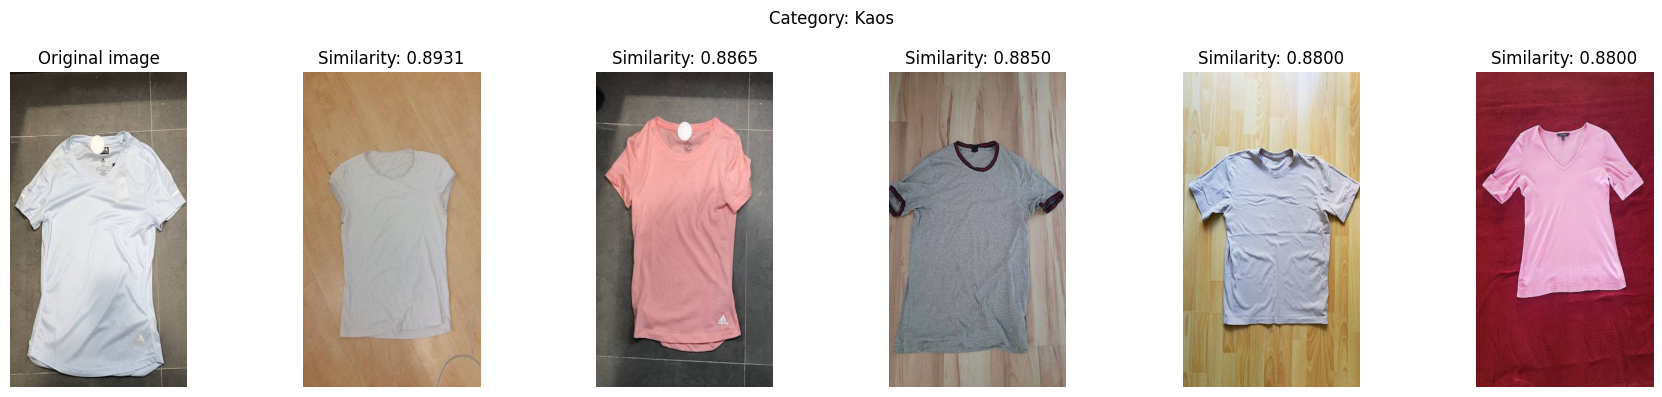

In [ ]:
test_indices = [2600, 3200, 3800, 4400, 4900]

for index in test_indices:
    show_similar_images_dinov2(index)

In [ ]:
relative_paths = np.array([
    os.path.relpath(path, dataset_path)
    for path in image_paths
])

np.savez_compressed(
    "dinov2_embeddings.npz",
    embeddings=normalized_dinov2_embeddings,
    image_paths=relative_paths,
    categories=categories,
    model_name="facebook/dinov2-small"
)

print("File saved successfully!")
print("Size:", round(os.path.getsize("dinov2_embeddings.npz") / (1024 * 1024), 2), "MB")

File saved successfully!
Size: 10.38 MB


In [ ]:
from google.colab import files

files.download("dinov2_embeddings.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
X = normalized_dinov2_embeddings
y = categories

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (6000, 384)
Test: (1500, 384)


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_cv = SVC(
    kernel="rbf",
    C=5,
    gamma="scale",
    class_weight={"Polo": 2.0},
    random_state=42
)

results_cv = cross_validate(
    svm_cv,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
    },
    n_jobs=-1
)

In [ ]:
print("Results by division:\n")

for i in range(5):
    print(f"Division {i + 1}:")
    print(f"Acuraccy: {results_cv['test_accuracy'][i]:.4f}")
    print(f"F1-macro: {results_cv['test_f1_macro'][i]:.4f}")
    print()

print("Averages:")

print(
    "Acuraccy:",
    results_cv["test_accuracy"].mean()
)

print(
    "F1-macro:",
    results_cv["test_f1_macro"].mean()
)


Results by division:

Division 1:
Acuraccy: 0.8350
F1-macro: 0.8343

Division 2:
Acuraccy: 0.8200
F1-macro: 0.8201

Division 3:
Acuraccy: 0.8083
F1-macro: 0.8069

Division 4:
Acuraccy: 0.8233
F1-macro: 0.8226

Division 5:
Acuraccy: 0.8342
F1-macro: 0.8344

Averages:
Acuraccy: 0.8241666666666665
F1-macro: 0.8236666969761405


In [ ]:
svm_model = SVC(
    kernel="rbf",
    C=5,
    gamma="scale",
    class_weight= {"Polo": 2.0},
    random_state=42
)

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

In [ ]:
print("Acuracy:", accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Acuracy: 0.8253333333333334

Classification report:
                precision    recall  f1-score   support

        Blazer       0.77      0.87      0.82       100
Celana_Panjang       0.88      0.79      0.83       100
 Celana_Pendek       0.90      0.92      0.91       100
          Gaun       0.83      0.87      0.85       100
        Hoodie       0.83      0.84      0.84       100
         Jaket       0.66      0.73      0.69       100
   Jaket_Denim       0.92      0.88      0.90       100
Jaket_Olahraga       0.81      0.73      0.77       100
         Jeans       0.89      0.88      0.88       100
          Kaos       0.87      0.89      0.88       100
        Kemeja       0.75      0.71      0.73       100
        Mantel       0.91      0.79      0.84       100
          Polo       0.73      0.70      0.71       100
           Rok       0.81      0.89      0.85       100
        Sweter       0.86      0.89      0.88       100

      accuracy                           0.83     

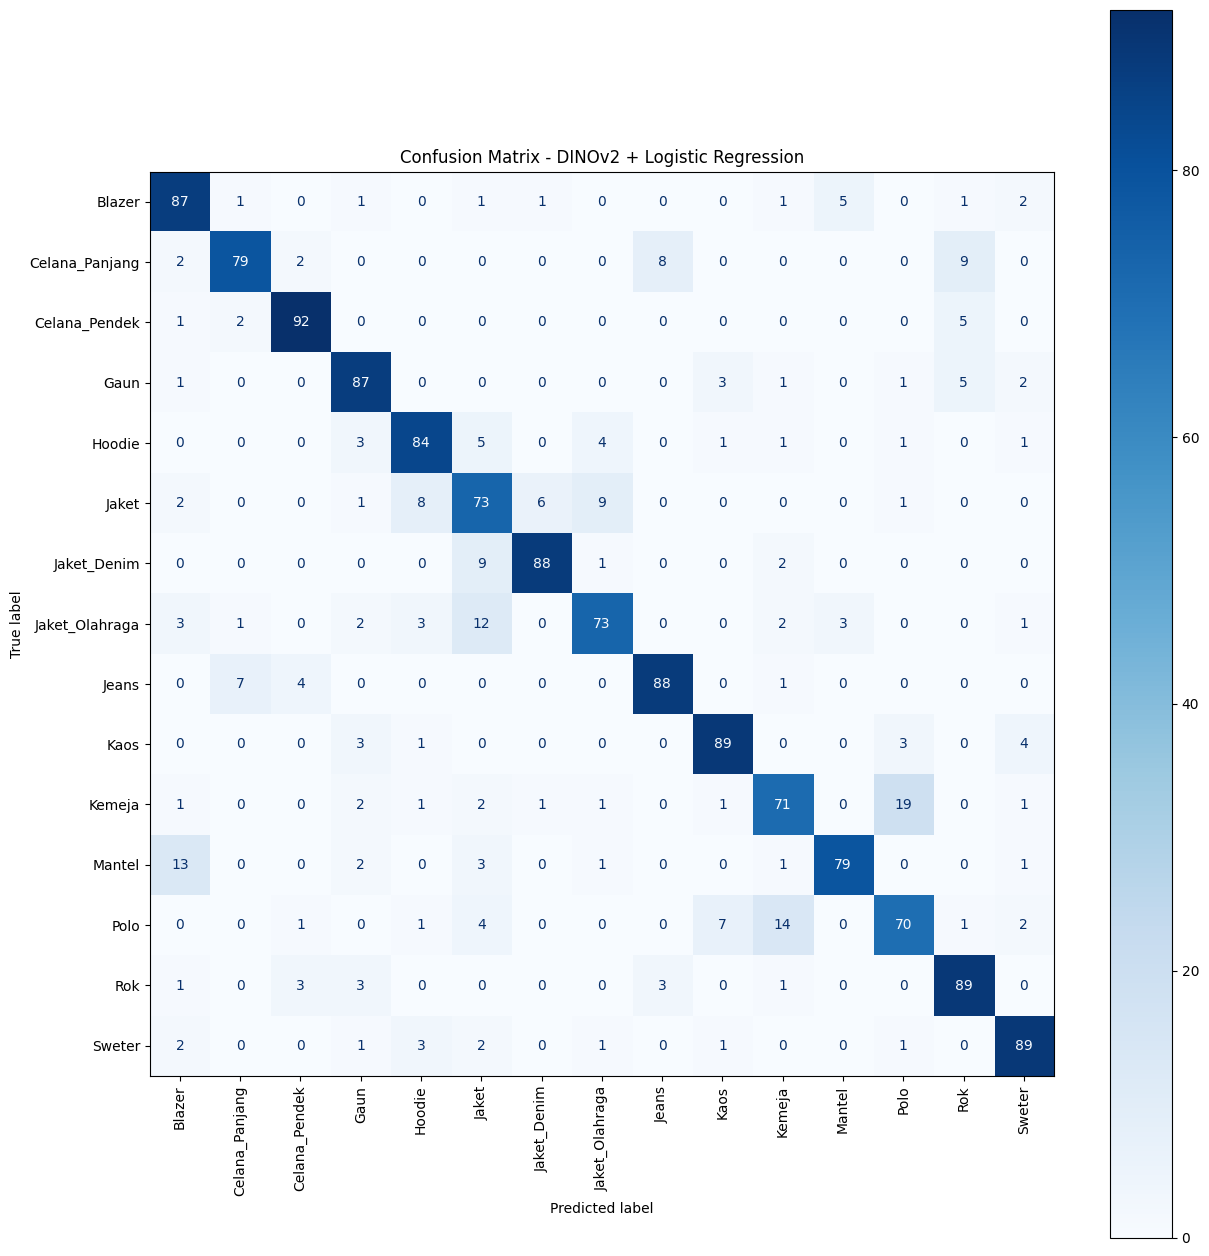

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=svm_model.classes_
)

fig, ax = plt.subplots(figsize=(13, 13))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - DINOv2 + Logistic Regression")
plt.tight_layout()
plt.show()

In [ ]:
# from sklearn.model_selection import GridSearchCV

# param_grid_2 = {
#     "C": [0.5, 1, 2, 5, 10, 20, 50, 100],
#     "gamma": ["scale", 0.0001, 0.001, 0.01, 0.1],
#     "kernel": ["rbf"]
# }

# grid_search_2 = GridSearchCV(
#     estimator=SVC(),
#     param_grid=param_grid_2,
#     cv=5,
#     scoring="f1_macro",
#     n_jobs=-1,
#     verbose=1
# )

# grid_search_2.fit(X_train, y_train)

# print("Melhores parâmetros:", grid_search_2.best_params_)
# print("Melhor F1-macro:", grid_search_2.best_score_)

In [ ]:
# svm_f1 = grid_search_2.best_estimator_

# y_pred_f1 = svm_f1.predict(X_test)

# print("Acurácia:", accuracy_score(y_test, y_pred_f1))

# print("\nRelatório de classificação:")
# print(classification_report(y_test, y_pred_f1))

In [ ]:
import joblib
import os

folder = "/content/drive/MyDrive/Clothes_project"

os.makedirs(folder, exist_ok=True)

joblib.dump(svm_model, os.path.join(folder, "svm_model.pkl"))


os.makedirs(folder, exist_ok=True)

relative_paths = np.array([
    os.path.relpath(path, dataset_path)
    for path in image_paths
])

np.savez_compressed(
    os.path.join(folder, "dinov2_embeddings.npz"),
    embeddings=normalized_dinov2_embeddings,
    image_paths=relative_paths,
    categories=categories,
    model_name="facebook/dinov2-small"
)

print(os.listdir(folder))

['svm_model.pkl', 'dinov2_embeddings.npz']


***From this point on, we will prepare the recommendation system.***

In [ ]:
import joblib
import os

In [ ]:
folder = "/content/drive/MyDrive/Clothes_project"

svm_model = joblib.load(os.path.join(folder, "svm_model.pkl"))

data = np.load(os.path.join(folder, "dinov2_embeddings.npz"))

In [ ]:
def extract_embedding(image):
    image = image.convert("RGB")

    inputs = processor(images=image, return_tensors="pt")
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = dinov2(**inputs)

    embedding = outputs.pooler_output

    embedding = embedding.cpu().numpy()

    embedding = embedding / np.maximum(
        np.linalg.norm(embedding, axis=1, keepdims=True),
        1e-10
    )

    return embedding

In [ ]:
embeddings = data["embeddings"]
categories = data["categories"]
image_paths = data["image_paths"]

In [ ]:
def recommend_clothing(test_embedding, categoria, top_n=5, query_index=None):

    similarities = embeddings @ test_embedding[0]

    category_mask = categories == categoria
    similarities[~category_mask] = -1

    if query_index is not None:
        similarities[query_index] = -1

    indices = np.argsort(similarities)[::-1][:top_n]

    return indices, similarities[indices]

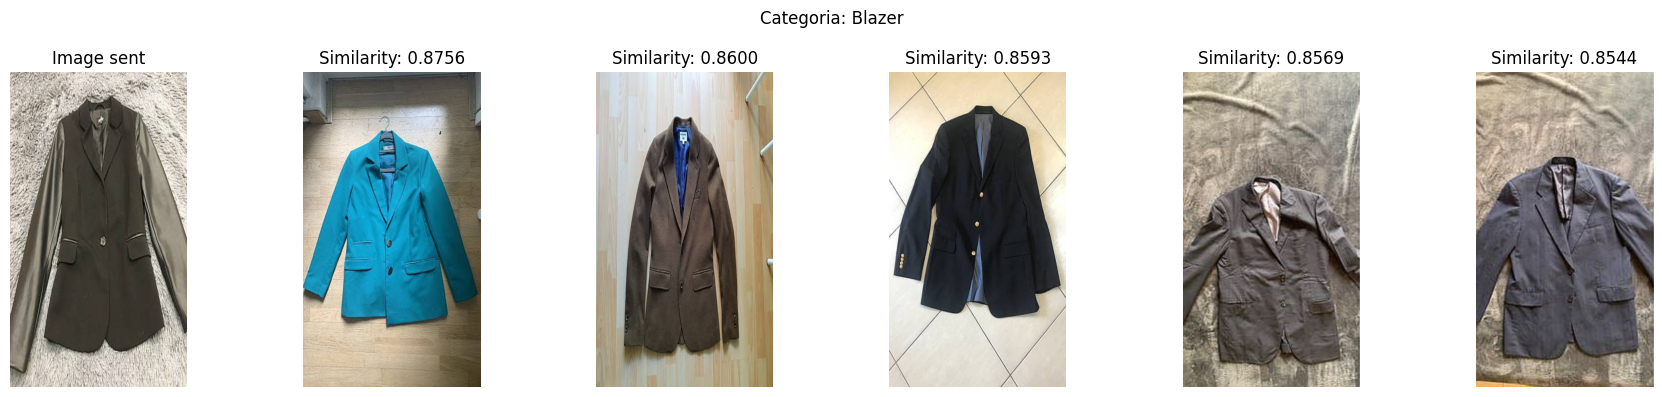

In [ ]:
indices, scores = recommend_clothing(
    test_embedding,
    predicted_category[0],
    top_n=5,
    query_index=100
)

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

axes[0].imshow(test_image)
axes[0].set_title("Image sent")
axes[0].axis("off")

for i, (indice, score) in enumerate(zip(indices, scores)):
    path = os.path.join(
        dataset_path,
        str(image_paths[indice])
    )

    imagem = Image.open(path).convert("RGB")

    axes[i + 1].imshow(imagem)
    axes[i + 1].set_title(f"Similarity: {score:.4f}")
    axes[i + 1].axis("off")

plt.suptitle(f"Categoria: {predicted_category[0]}")
plt.tight_layout()
plt.show()

Saving jaqueta.webp to jaqueta.webp


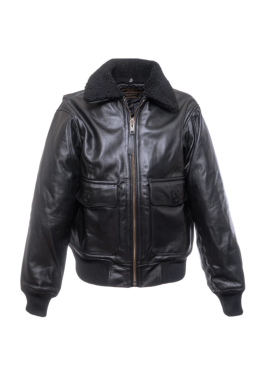

In [ ]:
from google.colab import files

uploaded = files.upload()

image_name = next(iter(uploaded))

external_image = Image.open(image_name).convert("RGB")

plt.imshow(external_image)
plt.axis("off")
plt.show()

In [ ]:
external_embedding = extract_embedding(external_image)

print("Embedding format:", external_embedding.shape)

predicted_category = svm_model.predict(external_embedding)

print("Category identified:", predicted_category[0])

Embedding format: (1, 384)
Category identified: Jaket_Denim


In [ ]:
indices, scores = recommend_clothing(
    external_embedding,
    predicted_category[0],
    top_n=5
)

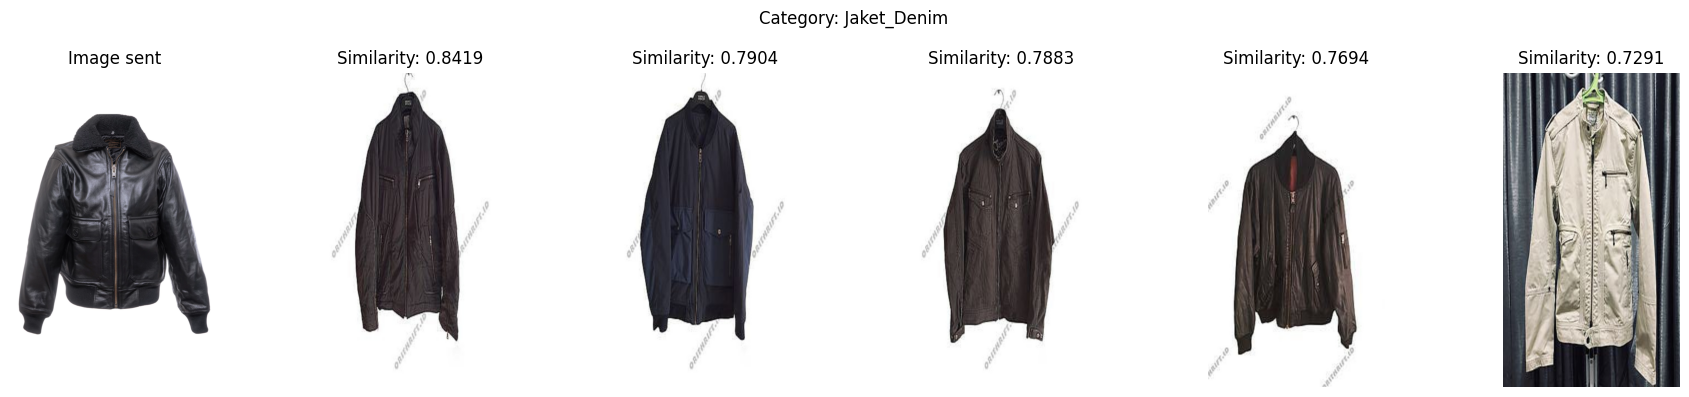

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))

axes[0].imshow(external_image)
axes[0].set_title("Image sent")
axes[0].axis("off")

for i, (index, score) in enumerate(zip(indices, scores)):

    image_path = os.path.join(
        dataset_path,
        str(image_paths[index])
    )

    recommended_image = Image.open(image_path).convert("RGB")

    axes[i + 1].imshow(recommended_image)
    axes[i + 1].set_title(f"Similarity: {score:.4f}")
    axes[i + 1].axis("off")

plt.suptitle(f"Category: {predicted_category[0]}")
plt.tight_layout()
plt.show()